# Previsão da qualidade do ar (AQI_Bucket) do dia seguinte — `city_day`

**Pergunta:** dado o que sabemos sobre o ar de **hoje** (poluentes, categoria do AQI, histórico recente), qual será a **categoria do AQI amanhã** em cada cidade?

**Pipeline**
1. Carga e ordenação
2. Calendário diário contínuo por cidade
3. Limpeza (negativos, colunas muito vazias, preenchimento só com o passado)
4. Alvo = categoria do dia seguinte
5. Features (hoje, defasagens, médias móveis, mês, cidade)
6. Divisão **temporal** (treino / validação / teste)
7. Pré-processamento (`ColumnTransformer`)
8. Baselines (persistência, Dummy, Regressão Logística)
9. Modelos (Árvore, Random Forest, KNN, SVM)
10. Ajuste de hiperparâmetros na validação (F1 macro): busca aleatória e **algoritmo genético**
11. Teste final (uma única vez) contra a persistência
12. Análise por cidade e importância das features
13. Conclusões

**Dados:** o dataset [Air Quality Data in India](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india) (`rohanrao/air-quality-data-in-india`) é baixado automaticamente com `kagglehub`; usamos o arquivo `city_day.csv`. Basta rodar as células em ordem.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit, ParameterGrid
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

# ----------------------------- CONFIGURAÇÃO -----------------------------
RANDOM_STATE = 42

TRAIN_END = '2018-12-31'          # treino: até esta data
VAL_END = '2019-12-31'            # validação: depois do treino até esta data; teste: depois disso

MAX_FALTANTES = 0.50              # descarta poluente com mais de 50% de valores ausentes
FFILL_LIMITE = 3                  # preenche no máximo 3 dias seguidos com o último valor conhecido
N_ITER_BUSCA = 10                 # nº de combinações testadas no ajuste de hiperparâmetros
ESCOLHER_MODELO = None            # None = escolhe o melhor na validação; ou ex.: 'RandomForest'

# Algoritmo genético (ajuste de hiperparâmetros de cada modelo)
USAR_GA = True                    # True: o teste final usa o melhor modelo do AG; False: usa a busca aleatória
GA_MODELOS = ['LogReg', 'DecisionTree', 'RandomForest', 'KNN', 'SVM']
GA_POP = 10                       # indivíduos por geração
GA_GER = 5                        # gerações
GA_ELITE = 2                      # melhores que passam direto para a próxima geração
GA_TORNEIO = 3                    # tamanho do torneio de seleção
GA_MUT = 0.30                     # probabilidade de mutar cada gene

ORDEM = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
MAPA = {c: i for i, c in enumerate(ORDEM)}
POLUENTES = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
POLUENTES_CHAVE = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3']   # recebem lags e médias móveis

## 1. Carga e ordenação
O dataset é baixado com `kagglehub` (na primeira vez pode levar alguns instantes; depois fica em cache). `Date` vira `datetime`, os dados são ordenados por `City` e `Date` e pares duplicados são removidos (a reindexação do próximo passo exige pares únicos).

In [2]:
import kagglehub   # no Colab já vem instalado; se faltar: !pip install kagglehub

path = kagglehub.dataset_download('rohanrao/air-quality-data-in-india')
print('Arquivos do dataset:', os.listdir(path))

DATA_PATH = os.path.join(path, 'city_day.csv')
df = pd.read_csv(DATA_PATH, parse_dates=['Date'])
df = df.sort_values(['City', 'Date']).drop_duplicates(['City', 'Date']).reset_index(drop=True)

print('Formato:', df.shape)
print('Período:', df['Date'].min().date(), '->', df['Date'].max().date())
print('Cidades:', df['City'].nunique())
print('Date dtype:', df['Date'].dtype)
print('AQI_Bucket ausente:', df['AQI_Bucket'].isna().sum())

fora = set(df['AQI_Bucket'].dropna().unique()) - set(ORDEM)
print('Categorias fora do esperado:', fora if fora else 'nenhuma')
df.head()

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Arquivos do dataset: ['stations.csv', 'station_hour.csv', 'city_day.csv', 'city_hour.csv', 'station_day.csv']
Formato: (29531, 16)
Período: 2015-01-01 -> 2020-07-01
Cidades: 26
Date dtype: datetime64[ns]
AQI_Bucket ausente: 4681
Categorias fora do esperado: nenhuma


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Calendário diário contínuo
Cada cidade passa a ter **uma linha por dia**, do seu primeiro ao seu último dia. Dias que faltavam entram com tudo `NaN`.
Isso garante que o `shift(-1)` do próximo passo sempre aponte para o dia seguinte de verdade.

In [3]:
partes = []
for cidade, g in df.groupby('City'):
    g = g.set_index('Date')
    dias = pd.date_range(g.index.min(), g.index.max(), freq='D')
    g = g.reindex(dias)
    g['City'] = cidade
    partes.append(g.rename_axis('Date').reset_index())

n_antes = len(df)
df = pd.concat(partes, ignore_index=True)

print(f'Linhas antes: {n_antes} | depois: {len(df)} | dias inseridos: {len(df) - n_antes}')

Linhas antes: 29531 | depois: 29531 | dias inseridos: 0


## 3. Limpeza
- Valores negativos de poluentes são impossíveis → viram `NaN`.
- Poluentes com muitos ausentes são descartados (a decisão usa só a taxa de ausência, não o alvo).
- Preenchimento com `ffill` **limitado**: usa só o passado (interpolação linear usaria valores futuros, o que seria vazamento).

In [4]:
df[POLUENTES] = df[POLUENTES].where(df[POLUENTES] >= 0)

falt = df[POLUENTES].isna().mean().sort_values(ascending=False)
print((falt * 100).round(1).to_string())

usadas = [p for p in POLUENTES if falt[p] <= MAX_FALTANTES]
descartadas = [p for p in POLUENTES if p not in usadas]
print('\nPoluentes usados:', usadas)
print('Poluentes descartados:', descartadas if descartadas else 'nenhum')

df[usadas] = df.groupby('City')[usadas].ffill(limit=FFILL_LIMITE)

Xylene     61.3
PM10       37.7
NH3        35.0
Toluene    27.2
Benzene    19.0
PM2.5      15.6
NOx        14.2
O3         13.6
SO2        13.1
NO2        12.1
NO         12.1
CO          7.0

Poluentes usados: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Poluentes descartados: ['Xylene']


## 4. Alvo: categoria do dia seguinte
`AQI_Bucket` é convertido para ordem numérica (0 = Good ... 5 = Severe). O alvo é essa categoria **deslocada um dia para trás dentro de cada cidade**.

In [5]:
df['bucket_hoje'] = df['AQI_Bucket'].map(MAPA)
df['alvo'] = df.groupby('City')['bucket_hoje'].shift(-1)

print('Linhas com alvo disponível:', df['alvo'].notna().sum(), 'de', len(df))
print(df['alvo'].map(dict(enumerate(ORDEM))).value_counts().reindex(ORDEM))

Linhas com alvo disponível: 24849 de 29531
alvo
Good            1341
Satisfactory    8224
Moderate        8829
Poor            2781
Very Poor       2337
Severe          1337
Name: count, dtype: int64


## 5. Features
Tudo o que entra aqui é conhecido **até hoje**:
- poluentes de hoje e `bucket_hoje` (categoria de hoje; a persistência vira também uma feature);
- defasagens de 1 e 2 dias e médias móveis de 3 e 7 dias dos poluentes-chave;
- `bucket_lag1` (categoria de ontem);
- mês em seno/cosseno (sazonalidade);
- `City` (One-Hot, feito dentro do pipeline).

In [6]:
for p in [c for c in POLUENTES_CHAVE if c in usadas]:
    g = df.groupby('City')[p]
    df[f'{p}_lag1'] = g.shift(1)
    df[f'{p}_lag2'] = g.shift(2)
    df[f'{p}_med3'] = g.transform(lambda s: s.rolling(3, min_periods=1).mean())
    df[f'{p}_med7'] = g.transform(lambda s: s.rolling(7, min_periods=1).mean())

df['bucket_lag1'] = df.groupby('City')['bucket_hoje'].shift(1)
df['mes_sin'] = np.sin(2 * np.pi * df['Date'].dt.month / 12)
df['mes_cos'] = np.cos(2 * np.pi * df['Date'].dt.month / 12)

derivadas = [c for c in df.columns if c.endswith(('_lag1', '_lag2', '_med3', '_med7')) and c != 'bucket_lag1']
num_log = usadas + derivadas                                  # passam por log1p + escala
num_plain = ['bucket_hoje', 'bucket_lag1', 'mes_sin', 'mes_cos']   # só imputação + escala
cat = ['City']
FEATURES = num_log + num_plain + cat
print(len(FEATURES), 'features')
print(FEATURES)

40 features
['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'PM2.5_lag1', 'PM2.5_lag2', 'PM2.5_med3', 'PM2.5_med7', 'PM10_lag1', 'PM10_lag2', 'PM10_med3', 'PM10_med7', 'NO2_lag1', 'NO2_lag2', 'NO2_med3', 'NO2_med7', 'CO_lag1', 'CO_lag2', 'CO_med3', 'CO_med7', 'SO2_lag1', 'SO2_lag2', 'SO2_med3', 'SO2_med7', 'O3_lag1', 'O3_lag2', 'O3_med3', 'O3_med7', 'bucket_hoje', 'bucket_lag1', 'mes_sin', 'mes_cos', 'City']


## 6. Divisão temporal
Treino no passado, validação no ano seguinte, teste no último período. **Sem sorteio**: misturar datas deixaria dias vizinhos (quase iguais) em treino e teste e inflaria o resultado.

Só entram linhas em que **hoje e amanhã** têm categoria conhecida; assim a persistência (amanhã = hoje) é definida para todas as linhas e a comparação com os modelos é justa.

> O período de teste (2020) inclui o **lockdown da covid** (ar bem mais limpo que o normal). Isso é um deslocamento de distribuição real e deve ser citado como limitação.

In [7]:
dados = df.dropna(subset=['alvo', 'bucket_hoje']).copy()
dados['alvo'] = dados['alvo'].astype(int)
dados['bucket_hoje'] = dados['bucket_hoje'].astype(int)

m_train = dados['Date'] <= TRAIN_END
m_val = (dados['Date'] > TRAIN_END) & (dados['Date'] <= VAL_END)
m_test = dados['Date'] > VAL_END

X_train, y_train = dados.loc[m_train, FEATURES], dados.loc[m_train, 'alvo']
X_val,   y_val   = dados.loc[m_val, FEATURES],   dados.loc[m_val, 'alvo']
X_test,  y_test  = dados.loc[m_test, FEATURES],  dados.loc[m_test, 'alvo']

assert min(len(X_train), len(X_val), len(X_test)) > 0, 'Alguma partição ficou vazia: revise TRAIN_END / VAL_END'

print(f'Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}')
dist = pd.DataFrame({
    'treino': y_train.value_counts(normalize=True),
    'validação': y_val.value_counts(normalize=True),
    'teste': y_test.value_counts(normalize=True),
}).reindex(range(len(ORDEM))).fillna(0)
dist.index = ORDEM
(dist * 100).round(1)

Treino: 13041 | Validação: 6968 | Teste: 4334


,treino,validação,teste
Good,2.9,5.8,12.0
Satisfactory,27.7,36.4,44.3
Moderate,36.4,35.2,33.5
Poor,13.1,10.7,6.4
Very Poor,12.8,7.1,3.0
Severe,7.2,4.8,0.8


## 7. Pré-processamento
Mesma ideia do seu notebook anterior (negativos → `NaN`, `log1p`, mediana, `RobustScaler`), agora em um `ColumnTransformer`:
- poluentes e derivadas: negativos → `NaN` → `log1p` → mediana → `RobustScaler`;
- `bucket_hoje`, `bucket_lag1`, mês: mediana → `RobustScaler`;
- `City`: One-Hot (cidades novas são ignoradas sem erro).

Tudo é ajustado **só no treino** (dentro do `Pipeline`).

In [8]:
def neg_para_nan(X):
    X = np.asarray(X, dtype=float).copy()
    X[X < 0] = np.nan
    return X

pipe_log = Pipeline([
    ('neg', FunctionTransformer(neg_para_nan)),
    ('log', FunctionTransformer(np.log1p)),
    ('imp', SimpleImputer(strategy='median')),
    ('esc', RobustScaler()),
])
pipe_plain = Pipeline([
    ('imp', SimpleImputer(strategy='median')),
    ('esc', RobustScaler()),
])

preprocessor = ColumnTransformer([
    ('log', pipe_log, num_log),
    ('plain', pipe_plain, num_plain),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
], sparse_threshold=0)

def make(clf):
    return Pipeline([('prep', clone(preprocessor)), ('clf', clf)])

print('Formato após pré-processar o treino:', clone(preprocessor).fit_transform(X_train).shape)

pesos = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
print('\nPesos de classe (referência; os modelos usam class_weight="balanced"):')
print({ORDEM[c]: round(w, 2) for c, w in zip(np.unique(y_train), pesos)})

Formato após pré-processar o treino: (13041, 57)

Pesos de classe (referência; os modelos usam class_weight="balanced"):
{'Good': np.float64(5.73), 'Satisfactory': np.float64(0.6), 'Moderate': np.float64(0.46), 'Poor': np.float64(1.27), 'Very Poor': np.float64(1.3), 'Severe': np.float64(2.33)}


## 8–9. Baselines e modelos (avaliados na validação)
- **Persistência:** prevê que amanhã será igual a hoje. É a régua principal: o modelo só vale a pena se superá-la em **F1 macro**.
- **Dummy** e **Regressão Logística** como referências simples.
- **Árvore, Random Forest, KNN e SVM** como modelos candidatos.

Métricas: F1 macro (principal, por causa do desbalanceamento), acurácia, acurácia balanceada e `adj` = fração de previsões a no máximo 1 categoria do valor real.

In [9]:
def avaliar(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'acc': accuracy_score(y_true, y_pred),
        'bal_acc': balanced_accuracy_score(y_true, y_pred),
        'adj': float(np.mean(np.abs(y_true - y_pred) <= 1)),
    }

MODELOS = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'LogReg': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                           n_jobs=-1, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'SVM': SVC(class_weight='balanced', random_state=RANDOM_STATE),
}

linhas = [{'modelo': 'Persistência', 'tempo_s': 0.0, **avaliar(y_val, X_val['bucket_hoje'].values)}]
ajustados = {}

for nome, clf in MODELOS.items():
    t0 = time.time()
    pipe = make(clf).fit(X_train, y_train)
    ajustados[nome] = pipe
    linhas.append({'modelo': nome, 'tempo_s': round(time.time() - t0, 1),
                   **avaliar(y_val, pipe.predict(X_val))})
    print(f'{nome} ok ({linhas[-1]["tempo_s"]}s)')

tab_val = pd.DataFrame(linhas).set_index('modelo').sort_values('f1_macro', ascending=False)
tab_val.round(3)

Dummy ok (0.2s)
LogReg ok (12.4s)
DecisionTree ok (1.6s)
RandomForest ok (27.7s)
KNN ok (0.2s)
SVM ok (9.8s)


,tempo_s,f1_macro,acc,bal_acc,adj
modelo,,,,,
SVM,9.8,0.675,0.699,0.725,0.990
Persistência,0.0,0.665,0.709,0.665,0.987
RandomForest,27.7,0.663,0.735,0.645,0.992
LogReg,12.4,0.656,0.691,0.713,0.984
KNN,0.2,0.575,0.671,0.560,0.982
DecisionTree,1.6,0.567,0.621,0.572,0.971
Dummy,0.2,0.087,0.352,0.167,0.823


Modelo escolhido para ajuste: SVM
F1 macro na validação: 0.675 | persistência: 0.665


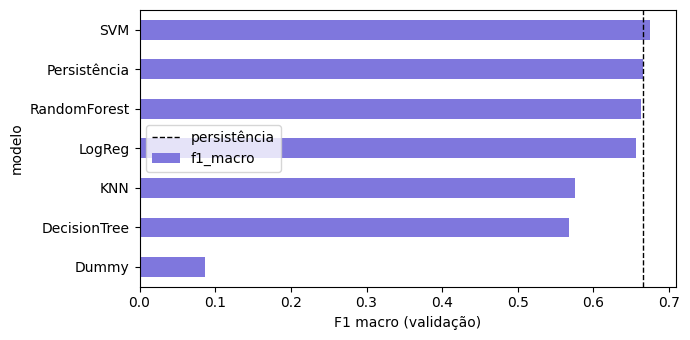

In [10]:
candidatos = tab_val.drop(index=['Persistência', 'Dummy'])
melhor_nome = ESCOLHER_MODELO or candidatos['f1_macro'].idxmax()
persist_f1 = tab_val.loc['Persistência', 'f1_macro']

print('Modelo escolhido para ajuste:', melhor_nome)
print(f'F1 macro na validação: {tab_val.loc[melhor_nome, "f1_macro"]:.3f} | persistência: {persist_f1:.3f}')
if tab_val.loc[melhor_nome, 'f1_macro'] <= persist_f1:
    print('Atenção: nenhum modelo superou a persistência na validação. Isso também é um resultado válido para o relatório.')

fig, ax = plt.subplots(figsize=(7, 3.5))
tab_val['f1_macro'].sort_values().plot.barh(ax=ax, color='#7F77DD')
ax.axvline(persist_f1, color='k', ls='--', lw=1, label='persistência')
ax.set_xlabel('F1 macro (validação)')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Ajuste de hiperparâmetros
Busca aleatória no modelo escolhido, usando como validação **exatamente o ano de validação** (`PredefinedSplit`, sem misturar datas) e F1 macro como métrica. Ao final, o melhor modelo é reajustado em treino + validação.

In [11]:
GRADES = {
    'LogReg': {'clf__C': [0.1, 1, 10]},
    'DecisionTree': {'clf__max_depth': [5, 10, 20, None], 'clf__min_samples_leaf': [1, 5, 20]},
    'RandomForest': {'clf__n_estimators': [200, 400], 'clf__max_depth': [10, 20, None],
                     'clf__min_samples_leaf': [1, 3, 5], 'clf__max_features': ['sqrt', 0.5]},
    'KNN': {'clf__n_neighbors': [5, 15, 31], 'clf__weights': ['uniform', 'distance']},
    'SVM': {'clf__C': [0.5, 1, 5, 10], 'clf__gamma': ['scale', 0.01, 0.1]},
}

grade = GRADES[melhor_nome]
n_iter = min(N_ITER_BUSCA, len(ParameterGrid(grade)))

X_tv = pd.concat([X_train, X_val])
y_tv = np.concatenate([y_train.values, y_val.values])
cv = PredefinedSplit(np.concatenate([np.full(len(X_train), -1), np.zeros(len(X_val), dtype=int)]))

busca = RandomizedSearchCV(
    make(MODELOS[melhor_nome]), grade, n_iter=n_iter, scoring='f1_macro', cv=cv,
    refit=True, n_jobs=1 if melhor_nome == 'RandomForest' else -1,
    random_state=RANDOM_STATE, verbose=1,
)
t0 = time.time()
busca.fit(X_tv, y_tv)

print(f'Tempo: {time.time() - t0:.0f}s')
print('Melhores parâmetros:', busca.best_params_)
print(f'F1 macro na validação: antes {tab_val.loc[melhor_nome, "f1_macro"]:.3f} -> depois {busca.best_score_:.3f}')

Fitting 1 folds for each of 10 candidates, totalling 10 fits
Tempo: 207s
Melhores parâmetros: {'clf__gamma': 0.01, 'clf__C': 5}
F1 macro na validação: antes 0.675 -> depois 0.687


## 10b. Ajuste por algoritmo genético (AG)
Em vez de sortear combinações independentes, o AG **evolui** uma população de configurações:

1. **Indivíduo** = um conjunto de hiperparâmetros (ex.: `max_depth=12`, `min_samples_leaf=3`).
2. **Aptidão** = F1 macro na validação (modelo treinado no treino).
3. **Seleção** por torneio, **cruzamento** uniforme (cada gene vem de um dos pais) e **mutação** (pequenos ajustes nos genes).
4. **Elitismo**: os melhores passam direto para a próxima geração.
5. Repete por `GA_GER` gerações; configurações já avaliadas ficam em cache (não são retreinadas).

O AG roda **para cada modelo**. O pré-processamento é ajustado uma vez no treino (ele não depende do modelo), o que acelera a busca. No fim, o melhor modelo é reajustado em treino + validação.

> Cuidado: como muitas configurações são comparadas no mesmo ano de validação, o F1 de validação do AG é um pouco otimista. A medida honesta continua sendo o **teste**, que o AG nunca vê.

In [12]:
# Espaço de busca de cada modelo: (tipo, limites). Tipos: int, float, float_log, cat
ESPACOS = {
    'LogReg':       {'C': ('float_log', 1e-3, 1e2)},
    'DecisionTree': {'max_depth': ('int', 3, 30), 'min_samples_leaf': ('int', 1, 50),
                     'min_samples_split': ('int', 2, 30)},
    'RandomForest': {'n_estimators': ('int', 100, 400), 'max_depth': ('int', 4, 30),
                     'min_samples_leaf': ('int', 1, 20), 'max_features': ('float', 0.2, 1.0)},
    'KNN':          {'n_neighbors': ('int', 3, 60), 'weights': ('cat', ['uniform', 'distance']),
                     'p': ('cat', [1, 2])},
    'SVM':          {'C': ('float_log', 0.1, 100), 'gamma': ('float_log', 1e-3, 1.0)},
}

def sortear(espaco, rng):
    ind = {}
    for gene, (tipo, *lim) in espaco.items():
        if tipo == 'int':
            ind[gene] = int(rng.integers(lim[0], lim[1] + 1))
        elif tipo == 'float':
            ind[gene] = float(rng.uniform(lim[0], lim[1]))
        elif tipo == 'float_log':
            ind[gene] = float(np.exp(rng.uniform(np.log(lim[0]), np.log(lim[1]))))
        else:
            ind[gene] = lim[0][int(rng.integers(len(lim[0])))]
    return ind

def cruzar(a, b, rng):
    return {g: (a if rng.random() < 0.5 else b)[g] for g in a}

def mutar(ind, espaco, rng, p):
    novo = dict(ind)
    for gene, (tipo, *lim) in espaco.items():
        if rng.random() >= p:
            continue
        if tipo == 'int':
            passo = max(1, int(round((lim[1] - lim[0]) * 0.15)))
            novo[gene] = int(np.clip(ind[gene] + rng.integers(-passo, passo + 1), lim[0], lim[1]))
        elif tipo == 'float':
            novo[gene] = float(np.clip(ind[gene] + rng.normal(0, 0.15 * (lim[1] - lim[0])), lim[0], lim[1]))
        elif tipo == 'float_log':
            novo[gene] = float(np.clip(ind[gene] * np.exp(rng.normal(0, 0.7)), lim[0], lim[1]))
        else:
            novo[gene] = lim[0][int(rng.integers(len(lim[0])))]
    return novo

def chave(ind):
    return tuple(sorted((k, round(v, 6) if isinstance(v, float) else v) for k, v in ind.items()))

def algoritmo_genetico(nome, Xtr, ytr, Xva, yva, seed):
    rng = np.random.default_rng(seed)
    espaco = ESPACOS[nome]
    cache = {}

    def aptidao(ind):
        k = chave(ind)
        if k not in cache:
            clf = clone(MODELOS[nome]).set_params(**ind)
            clf.fit(Xtr, ytr)
            cache[k] = f1_score(yva, clf.predict(Xva), average='macro', zero_division=0)
        return cache[k]

    pop = [sortear(espaco, rng) for _ in range(GA_POP)]
    historico = []
    for ger in range(GA_GER):
        notas = [aptidao(i) for i in pop]
        ordem = np.argsort(notas)[::-1]                      # melhor primeiro
        pop = [pop[i] for i in ordem]
        notas = [notas[i] for i in ordem]
        historico.append(notas[0])
        if ger == GA_GER - 1:
            break
        nova = pop[:GA_ELITE]                                # elitismo
        while len(nova) < GA_POP:
            pais = []
            for _ in range(2):                               # torneio: vence o de menor índice (= melhor)
                disputa = rng.choice(len(pop), size=min(GA_TORNEIO, len(pop)), replace=False)
                pais.append(pop[int(min(disputa))])
            nova.append(mutar(cruzar(pais[0], pais[1], rng), espaco, rng, GA_MUT))
        pop = nova
    return pop[0], notas[0], historico, len(cache)

LogReg: F1 val 0.654 | 20 configs avaliadas | 235.1s
DecisionTree: F1 val 0.662 | 34 configs avaliadas | 27.0s
RandomForest: F1 val 0.717 | 37 configs avaliadas | 2761.1s
KNN: F1 val 0.621 | 21 configs avaliadas | 97.9s
SVM: F1 val 0.691 | 33 configs avaliadas | 697.6s


,f1_val_padrao,f1_val_AG,ganho,avaliacoes,tempo_s
RandomForest,0.663,0.717,0.054,37.0,2761.1
SVM,0.675,0.691,0.016,33.0,697.6
DecisionTree,0.567,0.662,0.095,34.0,27.0
LogReg,0.656,0.654,-0.002,20.0,235.1
KNN,0.575,0.621,0.046,21.0,97.9



Melhores configurações encontradas:
  LogReg: {'C': 1.686248206155922}
  DecisionTree: {'max_depth': 30, 'min_samples_leaf': 36, 'min_samples_split': 14}
  RandomForest: {'n_estimators': 233, 'max_depth': 21, 'min_samples_leaf': 18, 'max_features': 0.9765584195159227}
  KNN: {'n_neighbors': 16, 'weights': 'distance', 'p': 1}
  SVM: {'C': 5.316725249428607, 'gamma': 0.008309128416649362}


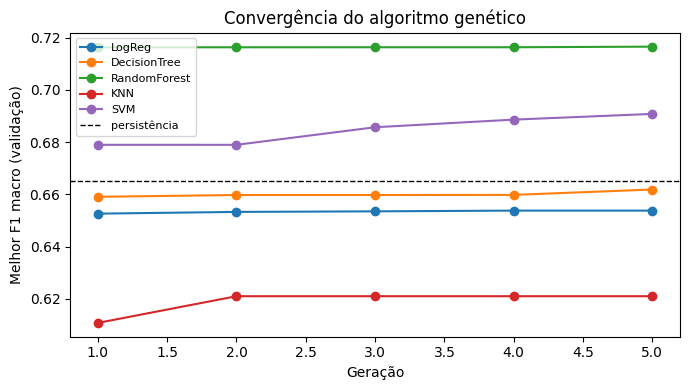

In [13]:
# Pré-processa uma única vez (o pré-processamento não depende do modelo)
prep = clone(preprocessor).fit(X_train)
Xtr_p, Xva_p = prep.transform(X_train), prep.transform(X_val)

resultados_ga = {}
for nome in GA_MODELOS:
    t0 = time.time()
    params, f1_val, hist, n_aval = algoritmo_genetico(nome, Xtr_p, y_train, Xva_p, y_val, seed=RANDOM_STATE)
    resultados_ga[nome] = {'params': params, 'f1_val': f1_val, 'hist': hist,
                           'avaliacoes': n_aval, 'tempo_s': round(time.time() - t0, 1)}
    print(f'{nome}: F1 val {f1_val:.3f} | {n_aval} configs avaliadas | {resultados_ga[nome]["tempo_s"]}s')

tab_ga = pd.DataFrame({
    n: {'f1_val_padrao': tab_val.loc[n, 'f1_macro'], 'f1_val_AG': r['f1_val'],
        'ganho': r['f1_val'] - tab_val.loc[n, 'f1_macro'],
        'avaliacoes': r['avaliacoes'], 'tempo_s': r['tempo_s']}
    for n, r in resultados_ga.items()
}).T.sort_values('f1_val_AG', ascending=False)
display(tab_ga.round(3))

print('\nMelhores configurações encontradas:')
for n, r in resultados_ga.items():
    print(f'  {n}: {r["params"]}')

fig, ax = plt.subplots(figsize=(7, 4))
for n, r in resultados_ga.items():
    ax.plot(range(1, len(r['hist']) + 1), r['hist'], marker='o', label=n)
ax.axhline(tab_val.loc['Persistência', 'f1_macro'], color='k', ls='--', lw=1, label='persistência')
ax.set_xlabel('Geração')
ax.set_ylabel('Melhor F1 macro (validação)')
ax.set_title('Convergência do algoritmo genético')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
# Melhor modelo do AG, reajustado em treino + validação (o teste continua intocado)
X_tv = pd.concat([X_train, X_val])
y_tv = np.concatenate([y_train.values, y_val.values])

ga_melhor_nome = tab_ga['f1_val_AG'].idxmax()
clf_ga = clone(MODELOS[ga_melhor_nome]).set_params(**resultados_ga[ga_melhor_nome]['params'])
ga_final = make(clf_ga).fit(X_tv, y_tv)

print('Melhor modelo pelo AG:', ga_melhor_nome)
print('Parâmetros:', resultados_ga[ga_melhor_nome]['params'])
print(f'F1 macro na validação: {resultados_ga[ga_melhor_nome]["f1_val"]:.3f} '
      f'(persistência: {tab_val.loc["Persistência", "f1_macro"]:.3f})')

Melhor modelo pelo AG: RandomForest
Parâmetros: {'n_estimators': 233, 'max_depth': 21, 'min_samples_leaf': 18, 'max_features': 0.9765584195159227}
F1 macro na validação: 0.717 (persistência: 0.665)


## 11. Teste final (uma única vez)
O modelo ajustado (pelo AG, se `USAR_GA = True`; senão pela busca aleatória) é avaliado no período de teste e comparado com a persistência.

,f1_macro,acc,bal_acc,adj
Persistência,0.696,0.774,0.699,0.994
RandomForest (AG),0.737,0.773,0.786,0.996


Ganho de F1 macro sobre a persistência: +0.041

Relatório por classe (modelo):
              precision    recall  f1-score   support

        Good       0.65      0.92      0.76       520
Satisfactory       0.84      0.77      0.80      1921
    Moderate       0.82      0.74      0.78      1450
        Poor       0.56      0.65      0.60       277
   Very Poor       0.66      0.75      0.70       131
      Severe       0.69      0.89      0.78        35

    accuracy                           0.77      4334
   macro avg       0.70      0.79      0.74      4334
weighted avg       0.79      0.77      0.77      4334



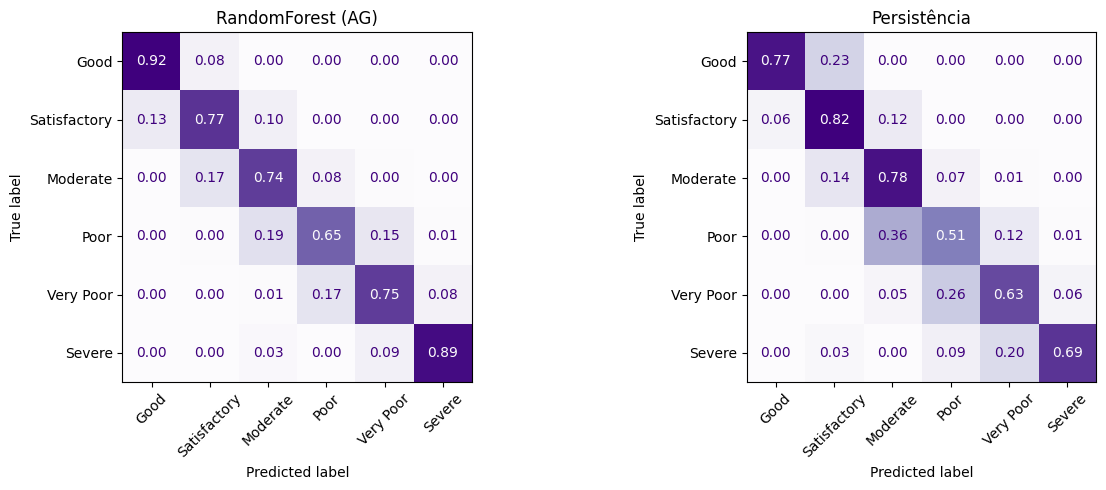

In [15]:
if USAR_GA:
    modelo_final, nome_final = ga_final, f'{ga_melhor_nome} (AG)'
else:
    modelo_final, nome_final = busca.best_estimator_, f'{melhor_nome} (busca aleatória)'
y_pred = modelo_final.predict(X_test)
y_pers = X_test['bucket_hoje'].values

tab_test = pd.DataFrame({
    'Persistência': avaliar(y_test, y_pers),
    nome_final: avaliar(y_test, y_pred),
}).T
display(tab_test.round(3))
print(f'Ganho de F1 macro sobre a persistência: {tab_test.iloc[1]["f1_macro"] - tab_test.iloc[0]["f1_macro"]:+.3f}')

print('\nRelatório por classe (modelo):')
print(classification_report(y_test, y_pred, labels=list(range(len(ORDEM))),
                            target_names=ORDEM, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (titulo, pred) in zip(axes, [(nome_final, y_pred), ('Persistência', y_pers)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=list(range(len(ORDEM))), display_labels=ORDEM,
        normalize='true', values_format='.2f', cmap='Purples', ax=ax,
        xticks_rotation=45, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

In [16]:
# Efeito do lockdown (25/03/2020): o desempenho muda entre antes e depois?
lockdown = pd.Timestamp('2020-03-25')
datas_teste = dados.loc[m_test, 'Date'].values
for rotulo, m in [('Teste antes do lockdown', datas_teste < np.datetime64(lockdown)),
                  ('Teste depois do lockdown', datas_teste >= np.datetime64(lockdown))]:
    if m.sum() == 0:
        print(rotulo, ': sem dados')
        continue
    r_mod = avaliar(y_test.values[m], y_pred[m])
    r_per = avaliar(y_test.values[m], y_pers[m])
    print(f'{rotulo} (n={m.sum()}): F1 macro modelo {r_mod["f1_macro"]:.3f} | persistência {r_per["f1_macro"]:.3f}')

Teste antes do lockdown (n=1965): F1 macro modelo 0.721 | persistência 0.654
Teste depois do lockdown (n=2369): F1 macro modelo 0.459 | persistência 0.541


## 12. Análise por cidade
Onde o modelo ajuda mais (ou menos) em relação à persistência? A coluna `ganho_acc` é a diferença de acurácia (modelo − persistência).

,n,acc_modelo,acc_persist,f1_modelo,ganho_acc
cidade,,,,,
Ahmedabad,171,0.532,0.690,0.487,-0.158
Patna,182,0.637,0.758,0.499,-0.121
Thiruvananthapuram,182,0.742,0.852,0.410,-0.110
Coimbatore,145,0.800,0.883,0.693,-0.083
Bengaluru,182,0.780,0.830,0.672,-0.049
Chennai,182,0.824,0.868,0.352,-0.044
Shillong,138,0.804,0.833,0.574,-0.029
Aizawl,109,0.899,0.917,0.841,-0.018
Bhopal,171,0.836,0.854,0.528,-0.018


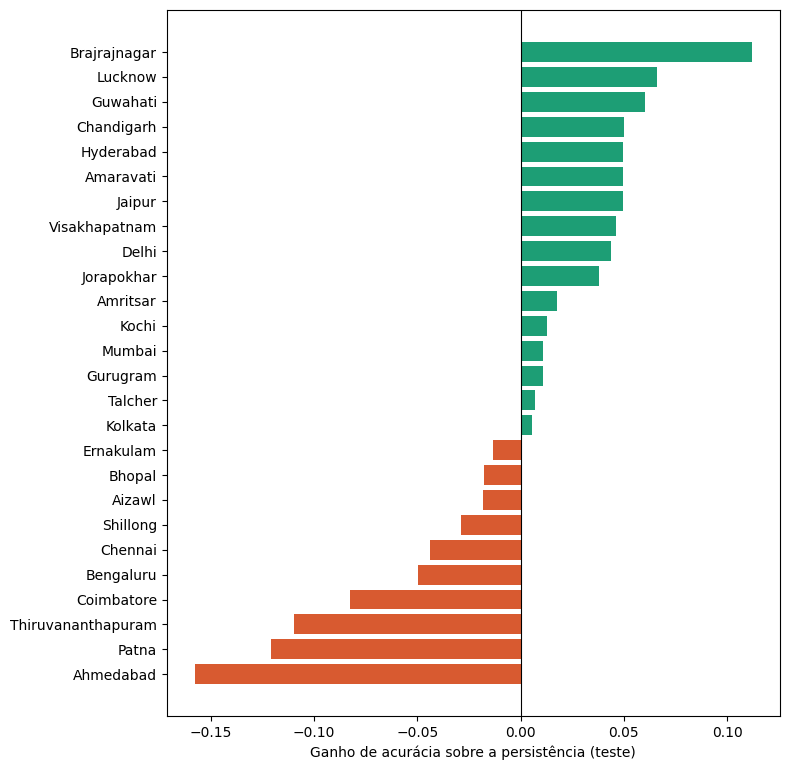

In [17]:
teste = dados.loc[m_test, ['City', 'alvo']].copy()
teste['pred'] = y_pred
teste['pers'] = y_pers

linhas = []
for cidade, g in teste.groupby('City'):
    linhas.append({
        'cidade': cidade, 'n': len(g),
        'acc_modelo': accuracy_score(g['alvo'], g['pred']),
        'acc_persist': accuracy_score(g['alvo'], g['pers']),
        'f1_modelo': f1_score(g['alvo'], g['pred'], average='macro', zero_division=0),
    })
por_cidade = pd.DataFrame(linhas).set_index('cidade')
por_cidade['ganho_acc'] = por_cidade['acc_modelo'] - por_cidade['acc_persist']
por_cidade = por_cidade.sort_values('ganho_acc')
display(por_cidade.round(3))

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(por_cidade))))
cores = ['#D85A30' if v < 0 else '#1D9E75' for v in por_cidade['ganho_acc']]
ax.barh(por_cidade.index, por_cidade['ganho_acc'], color=cores)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Ganho de acurácia sobre a persistência (teste)')
plt.tight_layout()
plt.show()

## Importância das features
Importância por permutação no teste: quanto o F1 macro cai quando uma feature é embaralhada. É calculada nas colunas originais (o pipeline cuida do pré-processamento), então `City` conta como um bloco só. Usa uma amostra para ser rápido.

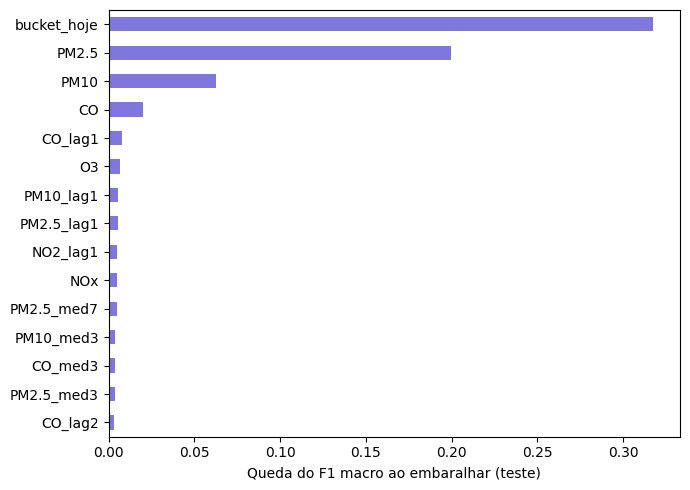

,0
bucket_hoje,0.3173
PM2.5,0.1998
PM10,0.0625
CO,0.0199
CO_lag1,0.0079
O3,0.0069
PM10_lag1,0.0053
PM2.5_lag1,0.0052
NO2_lag1,0.0052
NOx,0.0048


In [18]:
amostra = X_test.sample(min(2000, len(X_test)), random_state=RANDOM_STATE)
y_am = y_test.loc[amostra.index]

pi = permutation_importance(modelo_final, amostra, y_am, scoring='f1_macro',
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=amostra.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
imp.head(15).sort_values().plot.barh(ax=ax, color='#7F77DD')
ax.set_xlabel('Queda do F1 macro ao embaralhar (teste)')
plt.tight_layout()
plt.show()
imp.head(15).round(4)

## 13. Conclusões (preencha com os seus números)

- **Pergunta:** prever a categoria do AQI do dia seguinte por cidade.
- **Dados:** `city_day`, divisão temporal (treino ≤ 2018, validação 2019, teste 2020).
- **Referência:** persistência (amanhã = hoje) com F1 macro de ___ no teste.
- **Melhor modelo:** ___ (hiperparâmetros: ___), F1 macro de ___ no teste, ganho de ___ sobre a persistência.
- **Onde ajuda mais / menos:** cidades ___ (ganho) e ___ (perda).
- **Features mais importantes:** ___.
- **Limitações:** teste inclui o lockdown de 2020 (mudança de distribuição); classes extremas (`Good`, `Severe`) são raras; dias ausentes foram tratados por `ffill` limitado.
- **Próximos passos:** mais horizontes (2–3 dias), variáveis meteorológicas, modelos de séries temporais.